In [1]:
!pip install kaggle
# upload kaggle.json, download dataset
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
from google.colab import files
uploaded = files.upload()  # choose kaggle.json from your laptop

Saving Testing-selected-columns.csv to Testing-selected-columns (1).csv


In [3]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d kaushil268/disease-prediction-using-machine-learning
!unzip disease-prediction-using-machine-learning.zip
!ls

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/kaushil268/disease-prediction-using-machine-learning
License(s): DbCL-1.0
100% 29.8k/29.8k [00:00<00:00, 58.8MB/s]

Archive:  disease-prediction-using-machine-learning.zip
  inflating: Testing.csv             
  inflating: Training.csv            
 disease-prediction-using-machine-learning.zip
 sample_data
 Testing.csv
'Testing-selected-columns (1).csv'
 Testing-selected-columns.csv
 Training.csv


In [4]:
train_df = pd.read_csv('Training.csv')
test_df = pd.read_csv('Testing.csv')

# drop the extra empty unnamed column if it exists
if 'Unnamed: 133' in train_df.columns:
    train_df.drop('Unnamed: 133', axis=1, inplace=True)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

train_df.head()

Train shape: (4920, 133)
Test shape: (42, 133)


,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection


Missing values in train: 0
Missing values in test: 0

Number of diseases: 41

Disease distribution:
 prognosis
Fungal infection                           120
Allergy                                    120
GERD                                       120
Chronic cholestasis                        120
Drug Reaction                              120
Peptic ulcer diseae                        120
AIDS                                       120
Diabetes                                   120
Gastroenteritis                            120
Bronchial Asthma                           120
Hypertension                               120
Migraine                                   120
Cervical spondylosis                       120
Paralysis (brain hemorrhage)               120
Jaundice                                   120
Malaria                                    120
Chicken pox                                120
Dengue                                     120
Typhoid                                    

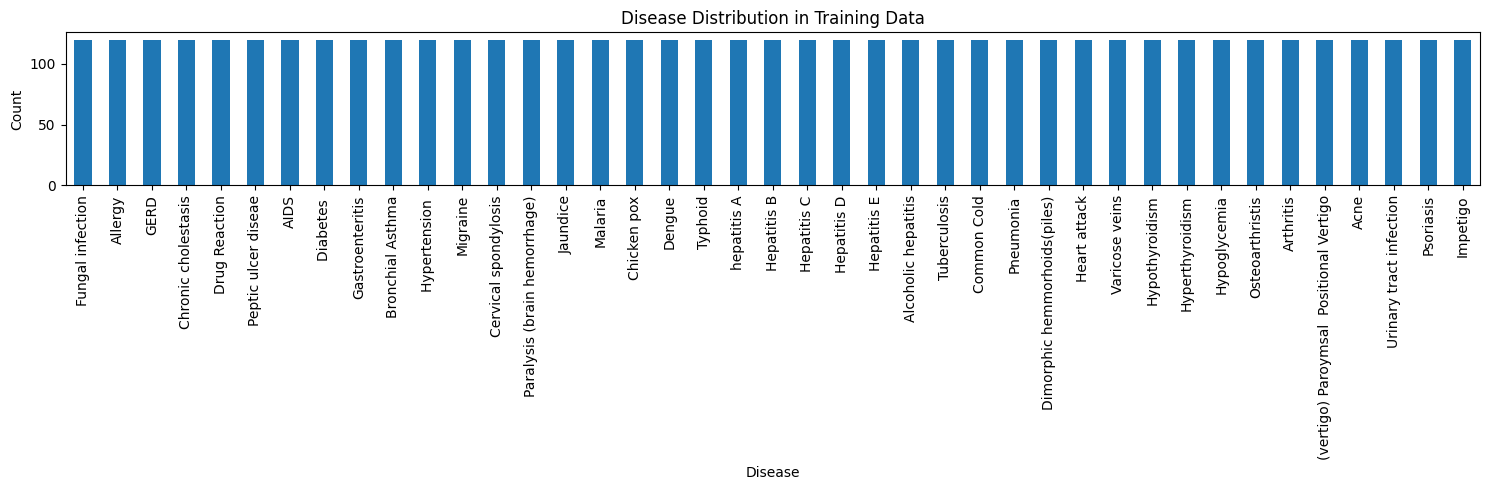

In [5]:
# check for missing values
print("Missing values in train:", train_df.isnull().sum().sum())
print("Missing values in test:", test_df.isnull().sum().sum())

# check number of unique diseases
print("\nNumber of diseases:", train_df['prognosis'].nunique())
print("\nDisease distribution:\n", train_df['prognosis'].value_counts())

# quick visualization
import matplotlib.pyplot as plt
train_df['prognosis'].value_counts().plot(kind='bar', figsize=(15,5))
plt.title('Disease Distribution in Training Data')
plt.xlabel('Disease')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

In [6]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

# fit on combined labels so train/test use the same encoding
le.fit(train_df['prognosis'])

X_train = train_df.drop('prognosis', axis=1)
y_train = le.transform(train_df['prognosis'])

X_test = test_df.drop('prognosis', axis=1)
y_test = le.transform(test_df['prognosis'])

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Classes:", le.classes_)

X_train shape: (4920, 132)
X_test shape: (42, 132)
Classes: ['(vertigo) Paroymsal  Positional Vertigo' 'AIDS' 'Acne'
 'Alcoholic hepatitis' 'Allergy' 'Arthritis' 'Bronchial Asthma'
 'Cervical spondylosis' 'Chicken pox' 'Chronic cholestasis' 'Common Cold'
 'Dengue' 'Diabetes ' 'Dimorphic hemmorhoids(piles)' 'Drug Reaction'
 'Fungal infection' 'GERD' 'Gastroenteritis' 'Heart attack' 'Hepatitis B'
 'Hepatitis C' 'Hepatitis D' 'Hepatitis E' 'Hypertension '
 'Hyperthyroidism' 'Hypoglycemia' 'Hypothyroidism' 'Impetigo' 'Jaundice'
 'Malaria' 'Migraine' 'Osteoarthristis' 'Paralysis (brain hemorrhage)'
 'Peptic ulcer diseae' 'Pneumonia' 'Psoriasis' 'Tuberculosis' 'Typhoid'
 'Urinary tract infection' 'Varicose veins' 'hepatitis A']


In [7]:
# Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

print("Models trained successfully!")

Models trained successfully!


In [8]:
# Random Forest predictions
rf_pred = rf.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)

# Decision Tree predictions
dt_pred = dt.predict(X_test)
dt_acc = accuracy_score(y_test, dt_pred)

print("Random Forest Accuracy:", rf_acc)
print("Decision Tree Accuracy:", dt_acc)

print("\n--- Random Forest Report ---")
print(classification_report(y_test, rf_pred, target_names=le.classes_))

print("\n--- Decision Tree Report ---")
print(classification_report(y_test, dt_pred, target_names=le.classes_))

Random Forest Accuracy: 0.9761904761904762
Decision Tree Accuracy: 0.9761904761904762

--- Random Forest Report ---
                                         precision    recall  f1-score   support

(vertigo) Paroymsal  Positional Vertigo       1.00      1.00      1.00         1
                                   AIDS       1.00      1.00      1.00         1
                                   Acne       1.00      1.00      1.00         1
                    Alcoholic hepatitis       1.00      1.00      1.00         1
                                Allergy       1.00      1.00      1.00         1
                              Arthritis       1.00      1.00      1.00         1
                       Bronchial Asthma       1.00      1.00      1.00         1
                   Cervical spondylosis       1.00      1.00      1.00         1
                            Chicken pox       1.00      1.00      1.00         1
                    Chronic cholestasis       1.00      1.00      1.00   

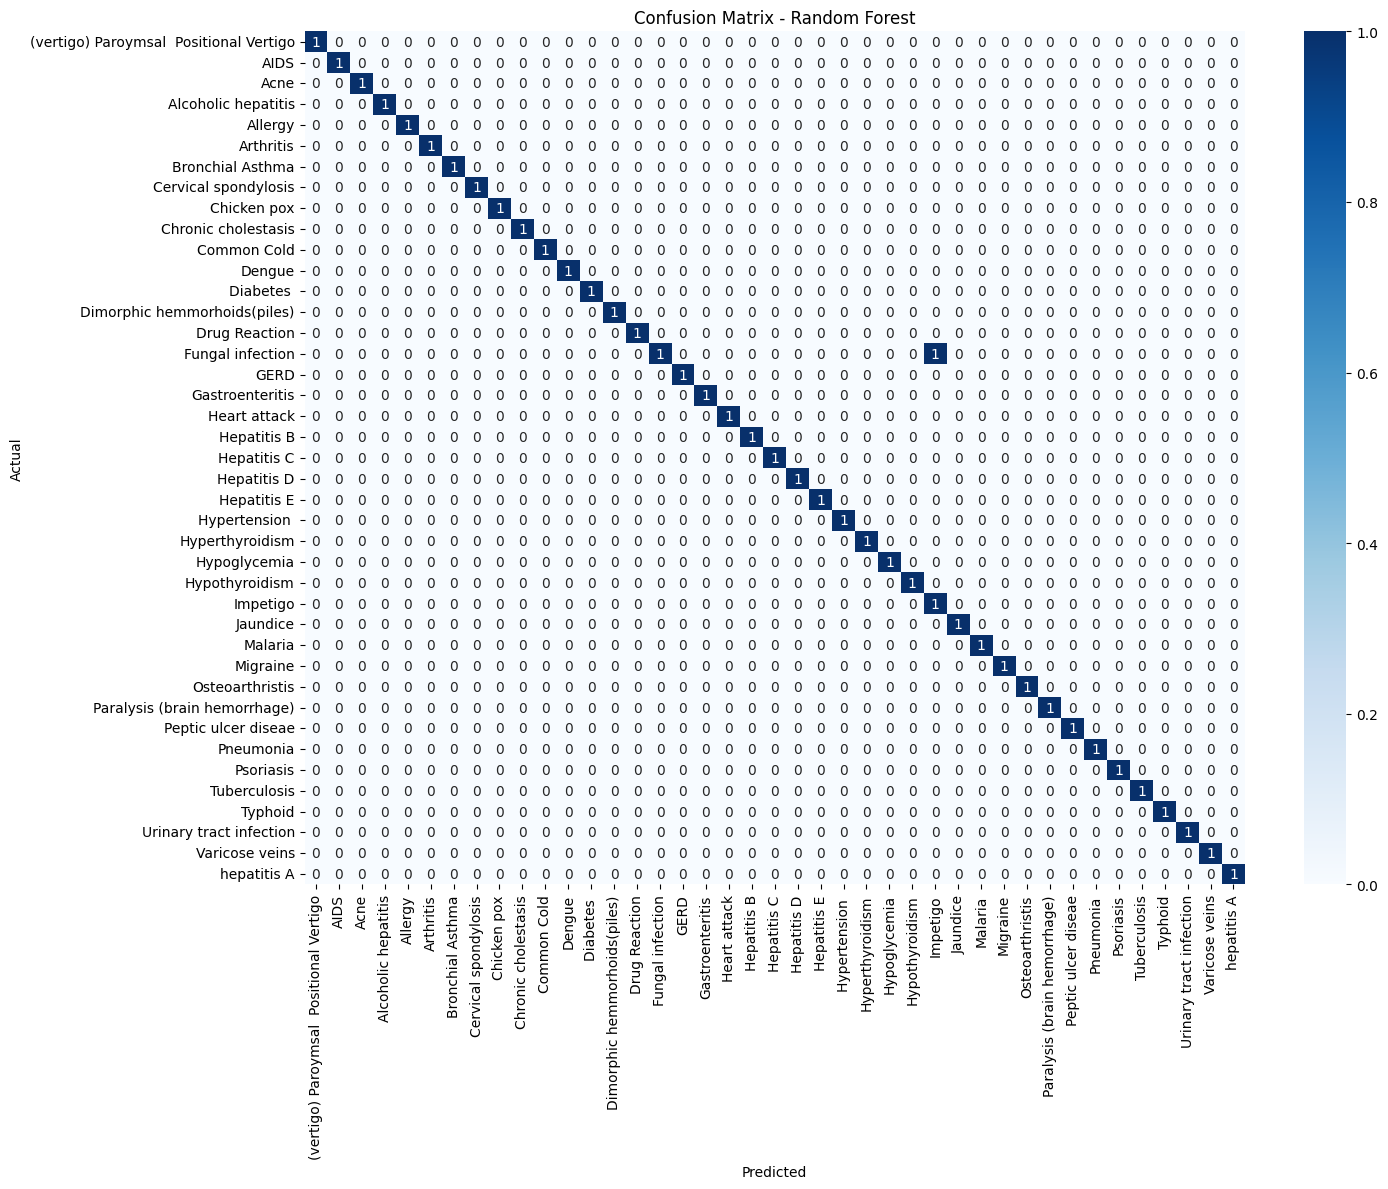

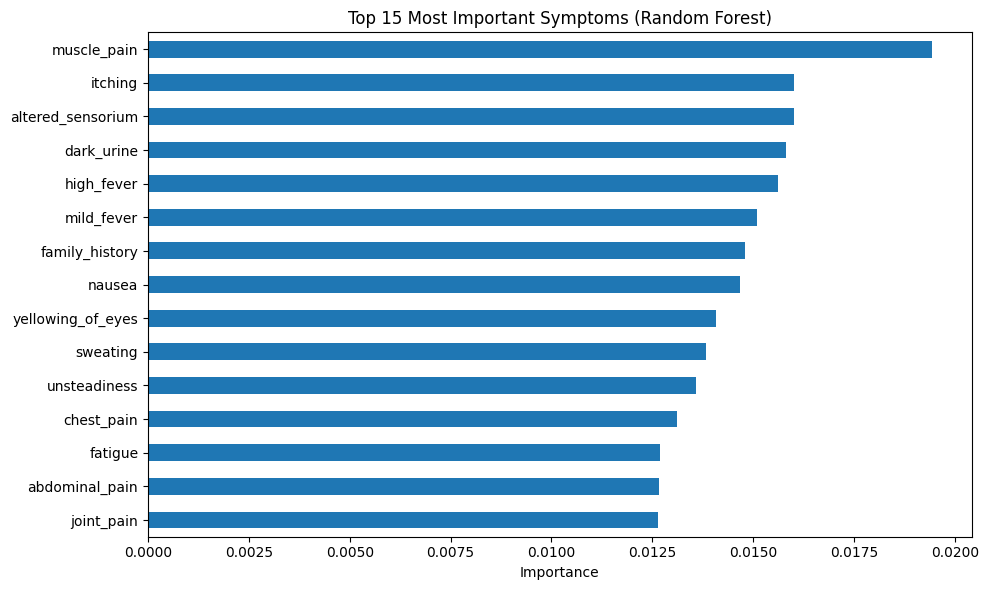

In [9]:
import seaborn as sns

# Confusion matrix for Random Forest
plt.figure(figsize=(15,12))
cm = confusion_matrix(y_test, rf_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Feature importance - top 15 symptoms
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
top_features = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(10,6))
top_features.plot(kind='barh')
plt.title('Top 15 Most Important Symptoms (Random Forest)')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [10]:
def predict_disease(symptoms_list, model=rf):
    """
    symptoms_list: list of symptom names (must match column names exactly)
    Returns predicted disease and top 3 probable diseases with confidence
    """
    # create input vector of zeros
    input_vector = pd.Series(0, index=X_train.columns)

    # set 1 for symptoms present
    for symptom in symptoms_list:
        if symptom in input_vector.index:
            input_vector[symptom] = 1
        else:
            print(f"Warning: '{symptom}' not found in symptom list")

    input_df = pd.DataFrame([input_vector])

    # predict
    prediction = model.predict(input_df)[0]
    probabilities = model.predict_proba(input_df)[0]

    predicted_disease = le.inverse_transform([prediction])[0]

    # top 3 most probable diseases
    top3_idx = np.argsort(probabilities)[-3:][::-1]
    top3_diseases = le.inverse_transform(top3_idx)
    top3_probs = probabilities[top3_idx]

    print(f"Predicted Disease: {predicted_disease}\n")
    print("Top 3 possibilities:")
    for disease, prob in zip(top3_diseases, top3_probs):
        print(f"  {disease}: {prob*100:.2f}%")

    return predicted_disease

# test it
test_symptoms = ['itching', 'skin_rash', 'nodal_skin_eruptions']
predict_disease(test_symptoms)

Predicted Disease: Fungal infection

Top 3 possibilities:
  Fungal infection: 100.00%
  Varicose veins: 0.00%
  Urinary tract infection: 0.00%


'Fungal infection'

In [11]:
import joblib

joblib.dump(rf, 'disease_prediction_rf_model.pkl')
joblib.dump(le, 'label_encoder.pkl')
joblib.dump(list(X_train.columns), 'symptom_columns.pkl')

print("Model, encoder, and symptom list saved!")

# download them to your laptop
from google.colab import files
files.download('disease_prediction_rf_model.pkl')
files.download('label_encoder.pkl')
files.download('symptom_columns.pkl')

Model, encoder, and symptom list saved!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>